# Fraud Radar · 02 — Modeling

**Goal:** train a model that gives every transaction a **fraud risk score**, choose **when to raise an alert**
based on business cost, and explain **why** each alert was raised.

**Input:** `dataset/processed/train_merged.pkl` (created by `01_eda.ipynb`)
**Output:** a trained model + artifacts in `model/`, ready for the FastAPI backend

**Plan**
1. Time-based split into **train / validation / test**
2. Leakage-safe feature engineering
3. Three models: Logistic Regression (baseline) · Random Forest · XGBoost
4. Comparison with **PR-AUC** (not accuracy)
5. Decision threshold chosen by **business cost**
6. Final evaluation on the untouched **test** period, including **unseen cards**
7. Explainability with **SHAP**
8. Save the model and artifacts

## 0. Setup

In [4]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

PROCESSED = Path("../dataset/processed")
MODEL_DIR = Path("../model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

FRAUD, LEGIT, ACCENT, MUTED = "#dc5a96", "#2c9fc4", "#7b8fd6", "#8e9ac8"
MODEL_COLORS = {"Logistic Regression": MUTED, "Random Forest": LEGIT, "XGBoost": FRAUD}
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 13,
})

## 1. Load the merged data

In [5]:
df = pd.read_pickle(PROCESSED / "train_merged.pkl")
df = df.sort_values("TransactionDT").reset_index(drop=True)
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns · fraud rate {df['isFraud'].mean():.2%}")

590,540 rows × 438 columns · fraud rate 3.50%


## 2. Time-based split: train · validation · test

| Period | Share | Used for |
|---|---|---|
| **Train** | first 70% of the timeline | fitting the models |
| **Validation** | next 15% | comparing models, early stopping, choosing the threshold |
| **Test** | last 15% | **final, untouched** evaluation |

Choosing the threshold on validation and reporting on test avoids an optimistic result.

In [6]:
q70, q85 = df["TransactionDT"].quantile([0.70, 0.85])
df["split"] = np.select([df["TransactionDT"] <= q70, df["TransactionDT"] <= q85], ["train", "valid"], "test")

is_train, is_valid, is_test = (df["split"] == s for s in ("train", "valid", "test"))
print(df.groupby("split", sort=False).agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"),
                                          fraud_rate=("isFraud", "mean"), first_day=("day", "min"), last_day=("day", "max")))

       transactions  frauds  fraud_rate  first_day  last_day
split                                                       
train        413378   14538    0.035169          1       120
valid         88581    3042    0.034341        120       152
test          88581    3083    0.034804        152       182


## 3. Feature engineering

**Rules to avoid leakage**
- Only information available **at payment time**.
- Any statistic learned from the data (frequencies, averages) is computed on **train only** and then applied to validation and test.
- The raw card identifier `card1` is **removed**: with 98.9% of cards repeated across periods, a model could memorize
  "this card committed fraud before" instead of learning fraud **patterns**. We keep how common the card is instead.

**New features**

| Feature | Idea |
|---|---|
| `amt_log` | Amount on a log scale |
| `amt_cents` | Decimal part of the amount (unusual cents are common in some fraud) |
| `amt_is_tiny` | Amount below $1 → **card testing** pattern found in the EDA |
| `weekday` | Relative day of the week |
| `email_match` | Purchaser and recipient email domains are the same |
| `*_freq` | How common a card / address / email domain is (computed on train) |
| `amt_vs_card_mean` | Amount compared with the usual amount for that card (computed on train) |

In [7]:
amt = df["TransactionAmt"].astype("float32")
df["amt_log"] = np.log1p(amt)
df["amt_cents"] = (amt - np.floor(amt)).round(3).astype("float32")
df["amt_is_tiny"] = (amt < 1).astype("int8")
df["weekday"] = (df["day"] % 7).astype("int8")
if {"P_emaildomain", "R_emaildomain"}.issubset(df.columns):
    df["email_match"] = (df["P_emaildomain"].astype("object") == df["R_emaildomain"].astype("object")).astype("int8")

FREQ_COLS = [c for c in ("card1", "addr1", "P_emaildomain", "DeviceInfo") if c in df.columns]
freq_maps = {}
for col in FREQ_COLS:
    key = df[col].astype("object")
    freq_maps[col] = key[is_train].value_counts(normalize=True).to_dict()
    df[f"{col}_freq"] = key.map(freq_maps[col]).fillna(0).astype("float32")

card_mean = df.loc[is_train].groupby("card1")["TransactionAmt"].mean().to_dict()
df["amt_vs_card_mean"] = (amt / df["card1"].map(card_mean)).astype("float32")

print("New features added:", ["amt_log", "amt_cents", "amt_is_tiny", "weekday", "email_match"] + [f"{c}_freq" for c in FREQ_COLS] + ["amt_vs_card_mean"])

New features added: ['amt_log', 'amt_cents', 'amt_is_tiny', 'weekday', 'email_match', 'card1_freq', 'addr1_freq', 'P_emaildomain_freq', 'DeviceInfo_freq', 'amt_vs_card_mean']


### Encode categories and select columns
Tree models need numbers, so each text category gets an integer code (`-1` = missing). The category lists are saved so the
API can encode new transactions exactly the same way.

In [8]:
CAT_COLS = [c for c in df.columns if isinstance(df[c].dtype, pd.CategoricalDtype)]
categories = {c: [str(x) for x in df[c].cat.categories] for c in CAT_COLS}
for c in CAT_COLS:
    df[c] = df[c].cat.codes.astype("int16")

DROP = {"TransactionID", "isFraud", "TransactionDT", "day", "split", "card1"}
missing_train = df.loc[is_train].isna().mean()
too_empty = set(missing_train[missing_train > 0.90].index)

FEATURES = [c for c in df.columns if c not in DROP and c not in too_empty]
print(f"Categorical columns encoded: {len(CAT_COLS)}")
print(f"Dropped for being >90% empty in train: {len(too_empty)}")
print(f"Features used by the tree models: {len(FEATURES)}")

X_train, y_train = df.loc[is_train, FEATURES], df.loc[is_train, "isFraud"]
X_valid, y_valid = df.loc[is_valid, FEATURES], df.loc[is_valid, "isFraud"]
X_test,  y_test  = df.loc[is_test,  FEATURES], df.loc[is_test,  "isFraud"]

Categorical columns encoded: 31
Dropped for being >90% empty in train: 10
Features used by the tree models: 432


## 4. Models

### 4.1 Baseline — Logistic Regression
A simple, interpretable model with a handful of understandable features. Every other model has to beat it.

In [9]:
LR_NUM = [c for c in ("amt_log", "amt_is_tiny", "hour", "has_identity", "C1", "C13", "D1", "card1_freq", "P_emaildomain_freq") if c in FEATURES]
LR_CAT = [c for c in ("ProductCD", "card4", "card6", "DeviceType") if c in FEATURES]

baseline = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), LR_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), LR_CAT),
    ])),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

t0 = time.time()
baseline.fit(X_train[LR_NUM + LR_CAT], y_train)
print(f"Trained in {time.time() - t0:.0f}s")

Trained in 1s


### 4.2 Random Forest
Trained on a **random 30% sample** of the training period to keep training time reasonable on a laptop.
`class_weight="balanced_subsample"` gives frauds more weight inside each tree.

In [10]:
rf_sample = X_train.sample(frac=0.30, random_state=SEED).index
rf = RandomForestClassifier(
    n_estimators=300, max_depth=18, min_samples_leaf=5, max_features="sqrt",
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
)

t0 = time.time()
rf.fit(X_train.loc[rf_sample].fillna(-999), y_train.loc[rf_sample])
print(f"Trained on {len(rf_sample):,} rows in {time.time() - t0:.0f}s")

Trained on 124,013 rows in 17s


### 4.3 XGBoost
Gradient boosting usually performs best on tabular data like this. It handles missing values natively and uses
**early stopping**: it keeps adding trees only while PR-AUC on validation improves.

In [11]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=8,
    subsample=0.8, colsample_bytree=0.5, min_child_weight=5,
    scale_pos_weight=pos_weight, eval_metric="aucpr", early_stopping_rounds=100,
    tree_method="hist", n_jobs=-1, random_state=SEED,
)

t0 = time.time()
xgb.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=200)
print(f"Trained in {time.time() - t0:.0f}s · best number of trees: {xgb.best_iteration + 1}")

[0]	validation_0-aucpr:0.35632
[200]	validation_0-aucpr:0.54858
[400]	validation_0-aucpr:0.56600
[600]	validation_0-aucpr:0.57348
[800]	validation_0-aucpr:0.57986
[1000]	validation_0-aucpr:0.58498
[1200]	validation_0-aucpr:0.59018
[1400]	validation_0-aucpr:0.59673
[1600]	validation_0-aucpr:0.60376
[1800]	validation_0-aucpr:0.60912
[1999]	validation_0-aucpr:0.61343
Trained in 685s · best number of trees: 1992


## 5. Model comparison on validation

**PR-AUC** (area under the precision–recall curve) is the main metric: it focuses on how well the model finds the rare
fraud cases. For reference, a random model would score about the fraud rate (~3.5%).

In [12]:
scores_valid = {
    "Logistic Regression": baseline.predict_proba(X_valid[LR_NUM + LR_CAT])[:, 1],
    "Random Forest": rf.predict_proba(X_valid.fillna(-999))[:, 1],
    "XGBoost": xgb.predict_proba(X_valid)[:, 1],
}

comparison = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_valid, s), "ROC-AUC": roc_auc_score(y_valid, s)}
    for name, s in scores_valid.items()
}).T.sort_values("PR-AUC", ascending=False)
comparison.loc["Random (reference)"] = [y_valid.mean(), 0.5]
comparison

,PR-AUC,ROC-AUC
XGBoost,0.613477,0.917408
Random Forest,0.454121,0.870010
Logistic Regression,0.166208,0.759803
Random (reference),0.034341,0.500000


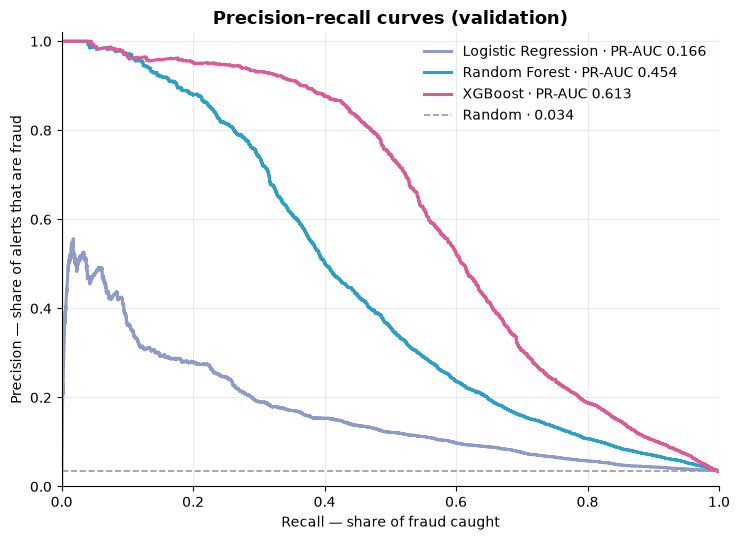

Best PR-AUC on validation: XGBoost


In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name, s in scores_valid.items():
    p, r, _ = precision_recall_curve(y_valid, s)
    ax.plot(r, p, color=MODEL_COLORS[name], lw=2.2, label=f"{name} · PR-AUC {average_precision_score(y_valid, s):.3f}")
ax.axhline(y_valid.mean(), color="#999", ls="--", lw=1.2, label=f"Random · {y_valid.mean():.3f}")
ax.set_title("Precision–recall curves (validation)")
ax.set_xlabel("Recall — share of fraud caught"); ax.set_ylabel("Precision — share of alerts that are fraud")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(loc="upper right", frameon=False)
plt.tight_layout(); plt.show()

WINNER = comparison.drop("Random (reference)").index[0]
BEST = "XGBoost"  # model deployed in the app (see note below)
print(f"Best PR-AUC on validation: {WINNER}")
if WINNER != BEST:
    print("⚠️ XGBoost is not the top model on validation — review the comparison before deploying it.")

**Model for the app: XGBoost.** It is expected to have the best PR-AUC, and as a tree model it can be explained
transaction by transaction with SHAP, which the dashboard needs. The rest of the notebook works with this model.

## 6. Choosing the decision threshold by business cost

The model returns a probability. We still need to decide **from which score we raise an alert**. Each mistake has a cost:

| Mistake | Cost assumption |
|---|---|
| **Missed fraud** (false negative) | The full transaction amount is lost |
| **False alarm** (false positive) | A manual review + customer friction, set at **$10** per alert |

The review cost is an **assumption** for this case study; a real company would use its own numbers.
We pick the threshold that **minimizes the total cost on validation**.

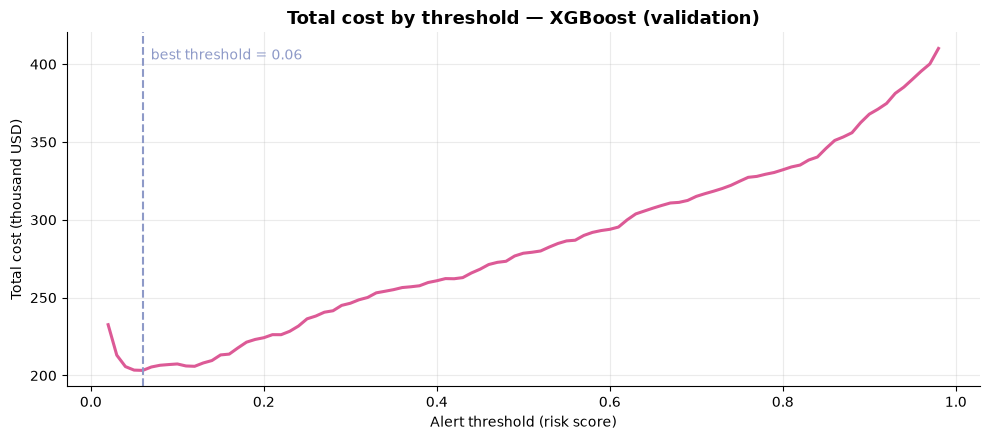

Cost with no model (all fraud is lost): $496,908
Cost with the model at threshold 0.06: $203,262 (59.1% lower)


In [14]:
REVIEW_COST = 10.0
best_model = {"Logistic Regression": baseline, "Random Forest": rf, "XGBoost": xgb}[BEST]

def score(model_name: str, X: pd.DataFrame) -> np.ndarray:
    if model_name == "Logistic Regression":
        return baseline.predict_proba(X[LR_NUM + LR_CAT])[:, 1]
    if model_name == "Random Forest":
        return rf.predict_proba(X.fillna(-999))[:, 1]
    return xgb.predict_proba(X)[:, 1]

def business_cost(y_true, scores, amounts, threshold):
    alert = scores >= threshold
    missed = (~alert) & (y_true == 1)
    false_alarm = alert & (y_true == 0)
    return amounts[missed].sum() + REVIEW_COST * false_alarm.sum()

s_valid = scores_valid[BEST]
amt_valid = df.loc[is_valid, "TransactionAmt"].to_numpy()
y_valid_np = y_valid.to_numpy()

thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
costs = np.array([business_cost(y_valid_np, s_valid, amt_valid, t) for t in thresholds])
THRESHOLD = float(thresholds[costs.argmin()])
no_model_cost = amt_valid[y_valid_np == 1].sum()

fig, ax = plt.subplots()
ax.plot(thresholds, costs / 1e3, color=FRAUD, lw=2.2)
ax.axvline(THRESHOLD, color=MUTED, ls="--")
ax.text(THRESHOLD, costs.max() / 1e3, f"  best threshold = {THRESHOLD:.2f}", color=MUTED, va="top")
ax.set_title(f"Total cost by threshold — {BEST} (validation)")
ax.set_xlabel("Alert threshold (risk score)"); ax.set_ylabel("Total cost (thousand USD)")
plt.tight_layout(); plt.show()

print(f"Cost with no model (all fraud is lost): ${no_model_cost:,.0f}")
print(f"Cost with the model at threshold {THRESHOLD:.2f}: ${costs.min():,.0f} ({1 - costs.min() / no_model_cost:.1%} lower)")

## 7. Final evaluation on the test period

This period was **never used** to train, compare or tune anything, so these are the numbers to report.

In [15]:
s_test = score(BEST, X_test)
y_test_np = y_test.to_numpy()
amt_test = df.loc[is_test, "TransactionAmt"].to_numpy()
alert = s_test >= THRESHOLD

results = {
    "model": BEST,
    "threshold": THRESHOLD,
    "test_transactions": int(len(y_test_np)),
    "test_fraud_rate": float(y_test_np.mean()),
    "pr_auc": float(average_precision_score(y_test_np, s_test)),
    "roc_auc": float(roc_auc_score(y_test_np, s_test)),
    "recall": float(recall_score(y_test_np, alert)),
    "precision": float(precision_score(y_test_np, alert, zero_division=0)),
    "fraud_amount_caught": float(amt_test[alert & (y_test_np == 1)].sum() / amt_test[y_test_np == 1].sum()),
    "alerts_per_1000": float(alert.mean() * 1000),
    "review_cost_assumption_usd": REVIEW_COST,
}

print(f"Model: {BEST} · threshold {THRESHOLD:.2f}\n")
print(f"PR-AUC:            {results['pr_auc']:.3f}   (random ≈ {results['test_fraud_rate']:.3f})")
print(f"ROC-AUC:           {results['roc_auc']:.3f}")
print(f"Recall:            {results['recall']:.1%} of fraudulent transactions caught")
print(f"Precision:         {results['precision']:.1%} of alerts are real fraud")
print(f"Fraud $ caught:    {results['fraud_amount_caught']:.1%} of the fraudulent amount")
print(f"Alert volume:      {results['alerts_per_1000']:.0f} alerts per 1,000 transactions")

Model: XGBoost · threshold 0.06

PR-AUC:            0.534   (random ≈ 0.035)
ROC-AUC:           0.897
Recall:            72.9% of fraudulent transactions caught
Precision:         20.7% of alerts are real fraud
Fraud $ caught:    72.9% of the fraudulent amount
Alert volume:      123 alerts per 1,000 transactions


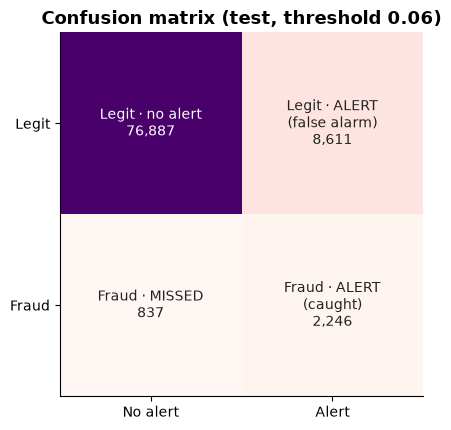

In [16]:
cm = confusion_matrix(y_test_np, alert)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap="RdPu")
labels = [["Legit · no alert", "Legit · ALERT\n(false alarm)"], ["Fraud · MISSED", "Fraud · ALERT\n(caught)"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "#222", fontsize=10)
ax.set_xticks([0, 1], ["No alert", "Alert"]); ax.set_yticks([0, 1], ["Legit", "Fraud"])
ax.set_title(f"Confusion matrix (test, threshold {THRESHOLD:.2f})"); ax.grid(False)
plt.tight_layout(); plt.show()

### How concentrated is the risk?
If analysts review the transactions with the highest scores first, how much fraud do they find?

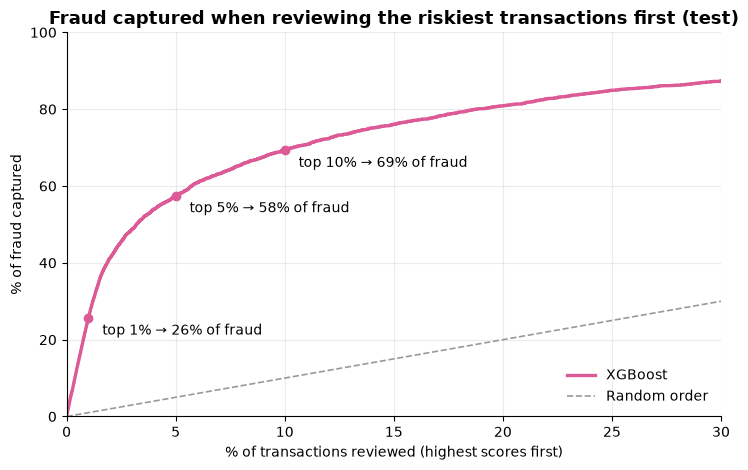

In [17]:
order = np.argsort(-s_test)
captured = np.cumsum(y_test_np[order]) / y_test_np.sum()
reviewed = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(reviewed * 100, captured * 100, color=FRAUD, lw=2.4, label=BEST)
ax.plot([0, 100], [0, 100], color="#999", ls="--", lw=1.2, label="Random order")
for pct in (1, 5, 10):
    k = int(len(order) * pct / 100)
    ax.scatter(pct, captured[k - 1] * 100, color=FRAUD, zorder=3)
    ax.annotate(f"top {pct}% → {captured[k - 1]:.0%} of fraud", (pct, captured[k - 1] * 100),
                textcoords="offset points", xytext=(10, -12))
ax.set_xlim(0, 30); ax.set_ylim(0, 100)
ax.set_title("Fraud captured when reviewing the riskiest transactions first (test)")
ax.set_xlabel("% of transactions reviewed (highest scores first)"); ax.set_ylabel("% of fraud captured")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

for pct in (1, 5, 10):
    results[f"fraud_captured_top_{pct}pct"] = float(captured[int(len(order) * pct / 100) - 1])

### Unseen cards
Most test transactions belong to cards already seen during training. A useful fraud model must also work on **new cards**,
so we evaluate both groups separately.

In [18]:
train_cards = set(df.loc[is_train, "card1"].dropna())
seen = df.loc[is_test, "card1"].isin(train_cards).to_numpy()

rows = []
for name, mask in (("Cards seen in train", seen), ("New cards", ~seen)):
    if mask.sum() > 0 and y_test_np[mask].sum() > 0:
        rows.append({"group": name, "transactions": int(mask.sum()), "frauds": int(y_test_np[mask].sum()),
                     "PR-AUC": average_precision_score(y_test_np[mask], s_test[mask]),
                     "recall": recall_score(y_test_np[mask], alert[mask])})
card_eval = pd.DataFrame(rows).set_index("group")
results["unseen_cards"] = card_eval.reset_index().to_dict(orient="records")
card_eval

,transactions,frauds,PR-AUC,recall
group,,,,
Cards seen in train,87371,3037,0.532071,0.727692
New cards,1210,46,0.695968,0.782609


## 8. Explainability with SHAP

SHAP shows how much each feature **pushes a transaction's score up or down**.
- **Global view:** which features matter most overall.
- **Local view:** the main reasons behind one specific alert — this is what the analyst will see in the dashboard.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


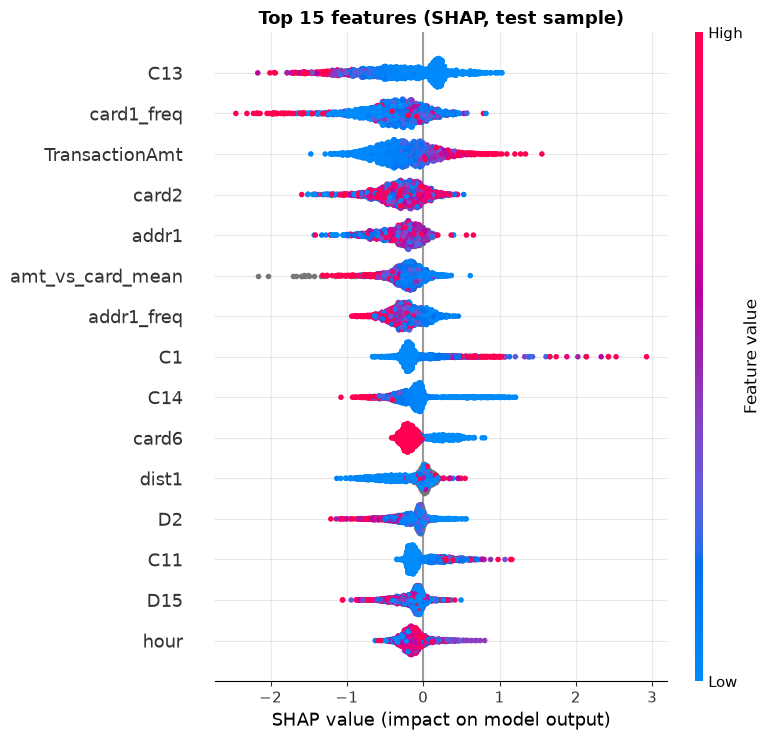

In [19]:
import shap

explainer = shap.TreeExplainer(xgb)
sample = X_test.sample(min(2000, len(X_test)), random_state=SEED)
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, max_display=15, show=False)
plt.title("Top 15 features (SHAP, test sample)", fontweight="bold")
plt.tight_layout(); plt.show()

In [23]:
READABLE = {
    "TransactionAmt": "Transaction amount", "amt_log": "Transaction amount", "amt_cents": "Unusual cents in amount",
    "amt_is_tiny": "Tiny amount (card testing)", "amt_vs_card_mean": "Amount vs. card's usual amount",
    "ProductCD": "Product type", "card4": "Card network", "card6": "Card type", "card1_freq": "How common the card is",
    "addr1_freq": "How common the address is", "P_emaildomain": "Purchaser email domain",
    "P_emaildomain_freq": "How common the email domain is", "R_emaildomain": "Recipient email domain",
    "email_match": "Purchaser and recipient emails match", "DeviceType": "Device type", "DeviceInfo": "Device",
    "DeviceInfo_freq": "How common the device is", "has_identity": "Identity data present", "hour": "Hour of day",
    "weekday": "Day of week", "dist1": "Distance between addresses",
}

def reasons(row: pd.DataFrame, top: int = 5) -> pd.DataFrame:
    sv = explainer.shap_values(row)[0]
    out = pd.DataFrame({"feature": row.columns, "value": row.iloc[0].values, "impact": sv})
    out = out.reindex(out["impact"].abs().sort_values(ascending=False).index).head(top)
    out["value"] = [categories[f][int(v)] if f in categories and v >= 0 else ("missing" if f in categories else v)
                    for f, v in zip(out["feature"], out["value"])]
    def describe(f):
        if f in READABLE: return READABLE[f]
        if f.startswith("V"): return f"Vesta risk signal ({f})"
        if f.startswith("C"): return f"Linked cards/addresses count ({f})"
        if f.startswith("D"): return f"Time since previous activity ({f})"
        if f.startswith("M"): return f"Match check ({f})"
        if f.startswith("id_"): return f"Device/identity signal ({f})"
        return f
    
    out["reason"] = out["feature"].map(describe)
    out["direction"] = np.where(out["impact"] > 0, "↑ raises risk", "↓ lowers risk")
    return out[["reason", "feature", "value", "impact", "direction"]]

top_alert = X_test.iloc[[int(np.argmax(np.where(y_test_np == 1, s_test, -1)))]]
print(f"Example: highest-scored fraud in test · risk score {xgb.predict_proba(top_alert)[0, 1]:.1%}")
reasons(top_alert)

Example: highest-scored fraud in test · risk score 100.0%


,reason,feature,value,impact,direction
306,Vesta risk signal (V258),V258,4.0,1.412174,↑ raises risk
197,Vesta risk signal (V149),V149,4.0,1.192354,↑ raises risk
25,Linked cards/addresses count (C14),C14,0.0,0.800514,↑ raises risk
24,Linked cards/addresses count (C13),C13,0.0,0.779564,↑ raises risk
204,Vesta risk signal (V156),V156,3.0,0.767922,↑ raises risk


## 9. Save the model and artifacts

Everything the backend needs to score a new transaction exactly like this notebook does.

In [21]:
artifacts = {
    "features": FEATURES,
    "categorical_columns": CAT_COLS,
    "categories": categories,
    "freq_maps": {c: {str(k): float(v) for k, v in m.items()} for c, m in freq_maps.items()},
    "card_mean": {str(k): float(v) for k, v in card_mean.items()},
    "threshold": THRESHOLD,
    "readable_names": READABLE,
}

joblib.dump(xgb, MODEL_DIR / "fraud_xgb.joblib")
joblib.dump(artifacts, MODEL_DIR / "artifacts.joblib")
with open(MODEL_DIR / "metrics.json", "w") as f:
    json.dump({"validation": comparison.round(4).to_dict(orient="index"), "test": results}, f, indent=2, default=float)

for p in sorted(MODEL_DIR.iterdir()):
    print(f"{p.name:<22} {p.stat().st_size / 1e6:6.1f} MB")

artifacts.joblib          0.5 MB
fraud_xgb.joblib         17.3 MB
metrics.json              0.0 MB


## 10. Results summary

Run the cell below and paste the output into the README's **Results** section.

In [22]:
print(f"| Metric (test period) | {BEST} |")
print("|---|---|")
print(f"| PR-AUC | {results['pr_auc']:.3f} (random ≈ {results['test_fraud_rate']:.3f}) |")
print(f"| ROC-AUC | {results['roc_auc']:.3f} |")
print(f"| Recall at threshold {THRESHOLD:.2f} | {results['recall']:.1%} |")
print(f"| Precision at threshold {THRESHOLD:.2f} | {results['precision']:.1%} |")
print(f"| Fraudulent amount caught | {results['fraud_amount_caught']:.1%} |")
print(f"| Fraud captured in top 5% riskiest | {results['fraud_captured_top_5pct']:.1%} |")
print(f"| Alerts per 1,000 transactions | {results['alerts_per_1000']:.0f} |")

| Metric (test period) | XGBoost |
|---|---|
| PR-AUC | 0.534 (random ≈ 0.035) |
| ROC-AUC | 0.897 |
| Recall at threshold 0.06 | 72.9% |
| Precision at threshold 0.06 | 20.7% |
| Fraudulent amount caught | 72.9% |
| Fraud captured in top 5% riskiest | 57.5% |
| Alerts per 1,000 transactions | 123 |
